# Stage 5 – Sensitivity and Uncertainty Analysis

**MMA3001 Project – Occupancy-driven ventilation assessment (Tom Gregory)**

Stage 4 found the minimum ventilation rates for G.20 using **nominal** input values. Several of those inputs are not measured; they are estimated or taken from the literature. This notebook asks how much the answers change when those inputs are wrong, and which input matters most.

**Outputs studied**

* $Q_{min,8h}$: smallest constant outdoor-air flow meeting the NCC limit (8-h mean ≤ 850 ppm). Nominal value 211.9 L/s.
* $Q_{min,peak}$: smallest constant flow keeping CO2 ≤ 1000 ppm at all times. Nominal value 443.7 L/s.
* $q_p$: the per-person rate needed by demand-controlled ventilation (DCV). Nominal value 12.06 L/s per person.

| Section | Content | Course link |
|---|---|---|
| A | Set-up and nominal results | |
| B | The uncertain inputs and their ranges | |
| C | An exact scaling law: four inputs, one curve | 7.2 (linear ODE), 3.1 (interpolation) |
| D | One-at-a-time sensitivity: tornado charts | 3.1, 3.4, 5.1 (controlled perturbation) |
| E | Local sensitivity: elasticities, and a check against theory | 2.2 (finite differences) |
| F | Monte Carlo uncertainty propagation | 6 (Monte Carlo), 5.5 |
| G | Numerical sensitivity: solver, time step, hold limits | 7.3, 7.4, 3.1 |
| H | Engineering interpretation and limitations | 7.2.13 |

**Runtime:** about 3 minutes. Section G3 also re-reads the raw data file (about 30 s) if it is in `data/raw/`; otherwise that section is skipped.

## A. Set-up and nominal results

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import occvent
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    import occvent

from occvent.cleaning import ResampleSettings, clean_events, resample_occupancy
from occvent.co2model import RoomParameters, occupancy_from_grid, step_mean_concentration
from occvent.config import ESTIMATED_VOLUME_M3, LOCAL_TIMEZONE, get_room
from occvent.design import CRITERIA, evaluate_ventilation, find_min_dcv_rate, find_min_ventilation, secant_bracketed
from occvent.io import load_processed, read_occupancy_events
from occvent.metrics import compliance_metrics
from occvent.sensitivity import (UNIT_ROOM, ResponseCurve, aggregate_occupancy, elasticities,
                                 oat_sensitivity, percentile_summary, sample_inputs, scaled_metric)
from occvent.solvers import explicit_euler, rk4

PROCESSED = ROOT / "data" / "processed" / "G20_occupancy_1min.csv.gz"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not PROCESSED.exists():
    raise FileNotFoundError(f"{PROCESSED} not found. Run `python -m occvent.prepare --raw data/raw/<zip>` first.")

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "ink": "#0b0b0b", "grey": "#52514e", "light": "#898781"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

grid = load_processed(PROCESSED)
occ, DT, _ = occupancy_from_grid(grid)
N_STEPS = occ.size

NOMINAL = {"V": ESTIMATED_VOLUME_M3["G20"], "G": 0.0052, "C_out": 420.0, "k": 1.0}
Q_FLOOR = 50.0      # DCV minimum flow [L/s], as in Stage 4
Q_DESIGN = 600.0    # 10 L/s x 60 design occupants, as in Stage 4


def q_min_full(criterion, V, G, C_out, k):
    # Full model: root finding (secant in 1/Q) with one exact two-year ODE solve per evaluation.
    p = RoomParameters(volume_m3=V, outdoor_co2_ppm=C_out, co2_generation_lps=G)
    return find_min_ventilation(k * occ, p, DT, criterion=criterion, variable="inverse",
                                bracket_lps=(20.0, 2000.0)).root


def q_p_full(V, G, C_out, k, floor=Q_FLOOR):
    # Full model: smallest DCV per-person rate meeting the 8-h criterion.
    # The controller responds to the *counted* people N, but CO2 comes from the
    # true number k N. A CO2 source of G * (k N) is the same as a source k G per
    # counted person, so the counted series is used with generation k G.
    p = RoomParameters(volume_m3=V, outdoor_co2_ppm=C_out, co2_generation_lps=k * G)
    return find_min_dcv_rate(occ, p, DT, q_floor_lps=floor).root


Q8_NOM = q_min_full("8h", **NOMINAL)
QP_NOM = q_min_full("peak", **NOMINAL)
print(f"occvent {occvent.__version__}; {N_STEPS:,} one-minute steps")
print(f"Nominal: Q_min,8h = {Q8_NOM:.1f} L/s, Q_min,peak = {QP_NOM:.1f} L/s (Stage 4: 211.9 and 443.7)")

occvent 0.6.0; 1,123,729 one-minute steps
Nominal: Q_min,8h = 211.9 L/s, Q_min,peak = 443.7 L/s (Stage 4: 211.9 and 443.7)


## B. The uncertain inputs

Each input gets a **range** (for the one-at-a-time study) and a **probability distribution** (for Monte Carlo). These are engineering judgements, stated here so they can be challenged.

| Input | Nominal | Range | Distribution | Basis |
|---|---|---|---|---|
| Room volume $V$ [m³] | 600 | 300–1200 | log-uniform | Estimated as about 200 m² × 3 m, with no drawings available. A factor of 2 either way; log-uniform treats "half" and "double" as equally likely |
| CO2 generation $G$ [L/s per person] | 0.0052 | 0.0040–0.0060 | triangular, mode 0.0052 | Seated to light office activity for adults (ASHRAE 62.1 / ASTM D6245 range; to confirm) |
| Outdoor CO2 $C_{out}$ [ppm] | 420 | 400–460 | uniform | Global background about 420–425 ppm in 2024–26; urban air can be tens of ppm higher; the NCC note uses 400 |
| Count factor $k$ [–] | 1.0 | 0.8–1.2 | triangular, mode 1.0 | Systematic people-counter error: true occupancy = $k$ × counted occupancy ($k$ > 1 means the sensor under-counts). No accuracy data were supplied, so ±20 % is assumed |
| DCV floor $Q_{floor}$ [L/s] (for $q_p$ only) | 50 | 25–100 | – | A design choice, not an uncertainty |

The ventilation rate $Q$ itself is not an uncertain *input* here: it is the design *output*.

In [2]:
RANGES = {"V": (300.0, 1200.0), "G": (0.0040, 0.0060), "C_out": (400.0, 460.0), "k": (0.8, 1.2)}
DISTRIBUTIONS = {"V": ("loguniform", 300.0, 1200.0),
                 "G": ("triangular", 0.0040, 0.0052, 0.0060),
                 "C_out": ("uniform", 400.0, 460.0),
                 "k": ("triangular", 0.8, 1.0, 1.2)}
LABELS = {"V": "Room volume V", "G": "CO2 generation G", "C_out": "Outdoor CO2 C_out",
          "k": "Count factor k", "floor": "DCV floor Q_floor"}
UNITS = {"V": "{:.0f} m³", "G": "{:.4f} L/s", "C_out": "{:.0f} ppm", "k": "{:.1f}", "floor": "{:.0f} L/s"}
print(pd.DataFrame({"nominal": NOMINAL, "low": {n: r[0] for n, r in RANGES.items()},
                    "high": {n: r[1] for n, r in RANGES.items()}}))

        nominal      low      high
V      600.0000  300.000  1200.000
G        0.0052    0.004     0.006
C_out  420.0000  400.000   460.000
k        1.0000    0.800     1.200


## C. An exact scaling law: four inputs, one curve

The CO2 model is **linear** (Notebook 7.2). Write $C = C_{out} + Y$, so $Y$ is the CO2 above outdoor level, with $Y(0) = 0$. With every count multiplied by $k$:

$$V\frac{dY}{dt} = 10^6\,G\,k\,N(t) - Q\,Y.$$

Now take a **unit room** ($V=1$, $G=1$, $k=1$, $C_{out}=0$) with flow $a = Q/V$, and call its solution $Z$:

$$\frac{dZ}{dt} = 10^6\,N(t) - a\,Z.$$

Substituting $Y = (kG/V)\,Z$ into the first equation gives the second, so this is exact. The worst 8-hour mean and the peak both scale the same way, so

$$\boxed{\text{metric}(V, G, C_{out}, k, Q) = C_{out} + \frac{k\,G}{V}\,M\!\left(\frac{Q}{V}\right)}$$

where $M(a)$ is the metric of the unit room. All four uncertain inputs collapse onto **one curve of one variable**, the volume-specific flow $a = Q/V$ [(L/s)/m³] (3.6 $a$ = air changes per hour). Three consequences:

1. $G$ and $k$ appear **only as the product $kG$**. A 10 % people-counter over-count has *exactly* the same effect as a 10 % higher CO2 generation rate.
2. $Q_{min}$ solves $M(a) = (\text{limit} - C_{out})\,V / (kG)$, and then $Q_{min} = aV$. Once $M(a)$ is tabulated, any combination of inputs needs only an **interpolation**, not a new set of ODE solves. This makes a large Monte Carlo study cheap (Section F).
3. The local log-log slope $\beta = -d\ln M/d\ln a$ controls every sensitivity (Section E). In a quasi-steady state $M \approx 10^6 \bar N / a$, so $\beta = 1$.

**Verification first:** the law is checked against the full model for random inputs.

Scaling law vs full model, 5 random input sets: max |difference| = 1.07e-10 ppm (round-off level)
Tabulated M(a) at 121 flows in 21.4 s (a = 0.05 to 10.0 (L/s)/m3, i.e. 0.18 to 36 ACH)
From the curve: Q_min,8h = 211.86 L/s, Q_min,peak = 443.68 L/s (full model 211.86, 443.68)
Local slope at the nominal design point: beta_8h = 0.983, beta_peak = 0.682


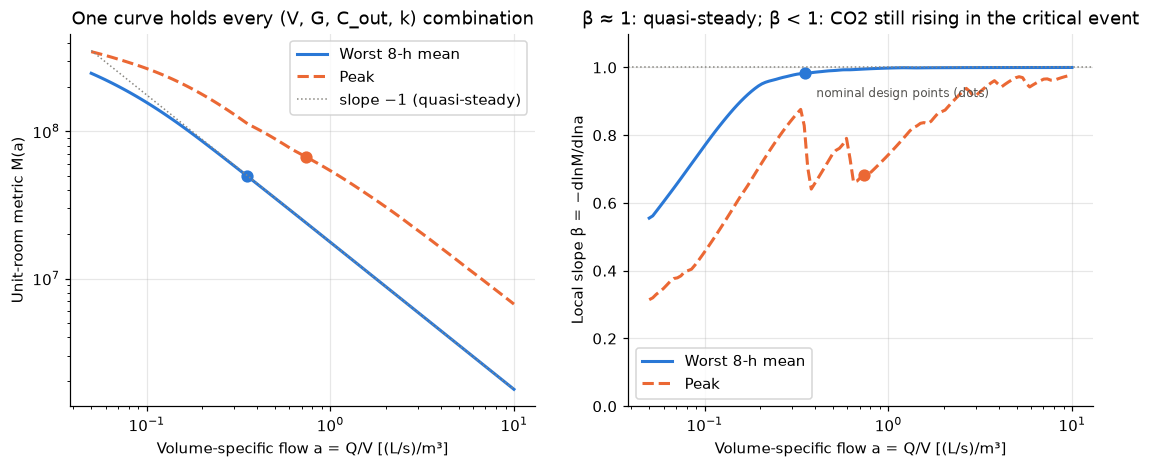

In [3]:
rng = np.random.default_rng(42)
errors = []
for _ in range(5):
    V, G, c_out, k = rng.uniform(300, 1200), rng.uniform(0.004, 0.006), rng.uniform(400, 460), rng.uniform(0.8, 1.2)
    q = rng.uniform(100, 800)
    full = evaluate_ventilation(k * occ, q, RoomParameters(V, c_out, G), DT)
    unit = evaluate_ventilation(occ, q / V, UNIT_ROOM, DT)
    for key in ("max_8h_mean_ppm", "peak_ppm"):
        errors.append(abs(full[key] - float(scaled_metric(unit[key], V, G, c_out, k))))
print(f"Scaling law vs full model, 5 random input sets: max |difference| = {max(errors):.2e} ppm (round-off level)")

t0 = time.perf_counter()
curve = ResponseCurve.build(occ, DT, a_grid=np.geomspace(0.05, 10.0, 121))
print(f"Tabulated M(a) at {curve.a.size} flows in {time.perf_counter() - t0:.1f} s "
      f"(a = {curve.a[0]} to {curve.a[-1]} (L/s)/m3, i.e. {3.6 * curve.a[0]:.2f} to {3.6 * curve.a[-1]:.0f} ACH)")
def q_min_curve(criterion, V, G, C_out, k):
    # Scaling law: Q_min by interpolation of the tabulated curve (no ODE solves).
    return curve.q_min(criterion, V, G, C_out, k)

print(f"From the curve: Q_min,8h = {float(q_min_curve('8h', **NOMINAL)):.2f} L/s, "
      f"Q_min,peak = {float(q_min_curve('peak', **NOMINAL)):.2f} L/s (full model {Q8_NOM:.2f}, {QP_NOM:.2f})")

def local_slope(criterion, a):
    # beta = -dlnM/dlna, central differences on the log-log table, interpolated to a.
    s = -np.gradient(np.log(curve.values[criterion]), np.log(curve.a))
    return float(np.interp(np.log(a), np.log(curve.a), s))

A_NOM = {"8h": Q8_NOM / NOMINAL["V"], "peak": QP_NOM / NOMINAL["V"]}
BETA = {c: local_slope(c, A_NOM[c]) for c in A_NOM}
print(f"Local slope at the nominal design point: beta_8h = {BETA['8h']:.3f}, beta_peak = {BETA['peak']:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for crit, color, ls, label in [("8h", C["blue"], "-", "Worst 8-h mean"), ("peak", C["orange"], "--", "Peak")]:
    ax1.loglog(curve.a, curve.values[crit], color=color, ls=ls, label=label)
    s = -np.gradient(np.log(curve.values[crit]), np.log(curve.a))
    ax2.semilogx(curve.a, s, color=color, ls=ls, label=label)
    for ax, y in [(ax1, np.exp(np.interp(np.log(A_NOM[crit]), np.log(curve.a), np.log(curve.values[crit])))),
                  (ax2, BETA[crit])]:
        ax.plot(A_NOM[crit], y, marker="o", color=color, ms=7, ls="none")
ref = curve.values["8h"][-1] * curve.a[-1] / curve.a
ax1.loglog(curve.a, ref, color=C["light"], lw=1, ls=":", label="slope −1 (quasi-steady)")
ax1.set_xlabel("Volume-specific flow a = Q/V [(L/s)/m³]")
ax1.set_ylabel("Unit-room metric M(a)")
ax1.set_title("One curve holds every (V, G, C_out, k) combination")
ax1.legend()
ax2.axhline(1, color=C["light"], lw=1, ls=":")
ax2.set_ylim(0, 1.1)
ax2.set_xlabel("Volume-specific flow a = Q/V [(L/s)/m³]")
ax2.set_ylabel("Local slope β = −dlnM/dlna")
ax2.set_title("β ≈ 1: quasi-steady; β < 1: CO2 still rising in the critical event")
ax2.text(A_NOM["8h"] * 1.15, BETA["8h"] - 0.07, "nominal design points (dots)", fontsize=8, color=C["grey"])
ax2.legend(loc="lower left")
save(fig, "stage5_scaling_curve")

**What this shows.** The law holds to round-off, so it is exact, not an approximation. The only approximation in later sections is the **interpolation** of the tabulated curve, which Section F checks against full root finding.

The slope $\beta$ tells us what kind of event sets each criterion:

* **8-hour criterion ($\beta$ close to 1):** set by long, sustained occupancy, where CO2 approaches a steady state. Steady-state CO2 does not depend on $V$, so $V$ hardly matters.
* **Peak criterion ($\beta$ well below 1):** set by short crowded events, during which CO2 is still rising. A larger room "absorbs" a short burst, so $V$ matters.

The peak curve's slope is **jagged** because the event that sets the peak changes as $a$ changes: a short, crowded event dominates at some flows and a longer one at others. The metric is continuous, but its slope jumps at these switches. This also limits the accuracy of interpolation and of local derivatives for the peak criterion slightly (Sections E and F).

## D. One-at-a-time sensitivity: tornado charts

Each input is moved to the low and then the high end of its range, with all other inputs held at nominal (the controlled-perturbation approach of 3.1, 3.4 and 5.1). Every value here uses the **full model**: root finding with a two-year ODE solve per evaluation. It does not use the scaling law, so it is an independent check on it.

In [4]:
t0 = time.perf_counter()
oat = {crit: oat_sensitivity(lambda crit=crit, **kw: q_min_full(crit, **kw), NOMINAL, RANGES) for crit in ("8h", "peak")}
nominal_dcv = {**NOMINAL, "floor": Q_FLOOR}
oat["dcv"] = oat_sensitivity(q_p_full, nominal_dcv, {**RANGES, "floor": (25.0, 100.0)})
print(f"OAT runs (full model) took {time.perf_counter() - t0:.0f} s\n")

titles = {"8h": "Q_min, NCC 8-h [L/s]", "peak": "Q_min, 1000 ppm peak [L/s]", "dcv": "DCV q_p [L/s per person]"}
for crit, table in oat.items():
    t = table.copy()
    t["change low [%]"] = 100 * (t["f_low"] / t["f_nominal"] - 1)
    t["change high [%]"] = 100 * (t["f_high"] / t["f_nominal"] - 1)
    print(f"{titles[crit]} (nominal {t['f_nominal'][0]:.2f})")
    print(t[["parameter", "low", "high", "f_low", "f_high", "change low [%]", "change high [%]"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

# Independent check: the scaling-law curve reproduces the full-model OAT values.
diffs = []
for crit in ("8h", "peak"):
    for _, row in oat[crit].iterrows():
        for side in ("low", "high"):
            x = {**NOMINAL, row["parameter"]: row[side]}
            diffs.append(100 * abs(float(q_min_curve(crit, **x)) / row[f"f_{side}"] - 1))
print(f"Scaling-law curve vs full model over all OAT points: max difference {max(diffs):.3f} %")

OAT runs (full model) took 61 s

Q_min, NCC 8-h [L/s] (nominal 211.86)
parameter   low  high  f_low  f_high  change low [%]  change high [%]
        k   0.8   1.2  168.7   254.9          -20.38            20.33
        G 0.004 0.006    162     245          -23.53            15.65
    C_out   400   460  202.3     234          -4.525            10.43
        V   300  1200  213.3   206.1          0.7021           -2.706 

Q_min, 1000 ppm peak [L/s] (nominal 443.68)
parameter   low  high  f_low  f_high  change low [%]  change high [%]
        k   0.8   1.2    325   575.2          -26.74            29.64
        G 0.004 0.006  308.6   544.9          -30.43            22.81
        V   300  1200  543.3   348.2           22.45           -21.52
    C_out   400   460  422.1   492.4          -4.864            10.98 

DCV q_p [L/s per person] (nominal 12.06)
parameter   low  high  f_low  f_high  change low [%]  change high [%]
        k   0.8   1.2  9.603    14.5           -20.4             20.2


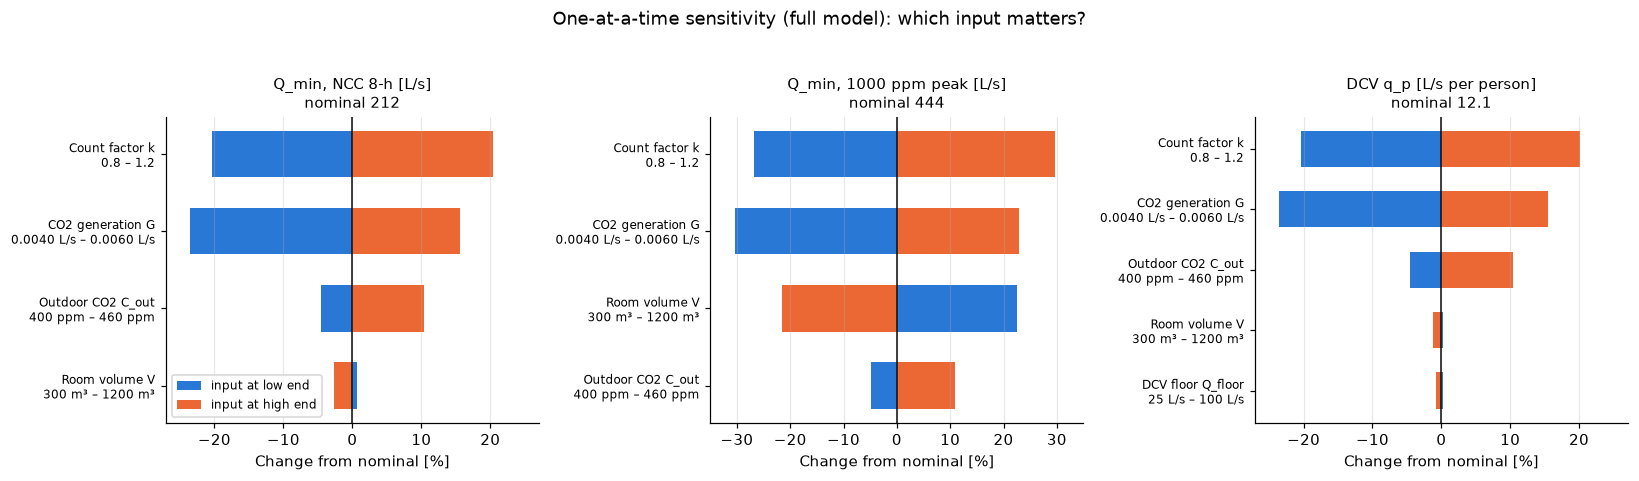

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (crit, table) in zip(axes, oat.items()):
    f0 = table["f_nominal"][0]
    t = table[::-1].reset_index(drop=True)          # largest swing at the top
    y = np.arange(len(t))
    lo_pct = 100 * (t["f_low"] / f0 - 1)
    hi_pct = 100 * (t["f_high"] / f0 - 1)
    ax.barh(y, lo_pct, color=C["blue"], height=0.6, label="input at low end")
    ax.barh(y, hi_pct, color=C["orange"], height=0.6, label="input at high end")
    ax.axvline(0, color=C["ink"], lw=1)
    ax.set_yticks(y, [f"{LABELS[p]}\n{UNITS[p].format(lo)} – {UNITS[p].format(hi)}"
                      for p, lo, hi in zip(t["parameter"], t["low"], t["high"])], fontsize=8)
    lim = max(5.0, 1.15 * float(np.max(np.abs(np.r_[lo_pct, hi_pct]))))
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("Change from nominal [%]")
    ax.set_title(f"{titles[crit]}\nnominal {f0:.3g}", fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("One-at-a-time sensitivity (full model): which input matters?", y=1.03)
fig.tight_layout()
save(fig, "stage5_tornado")

**What this shows.**

* **8-hour NCC criterion:** dominated by **$G$ and the count factor $k$**. They have the same effect per percent change, because only the product $kG$ matters (Section C). Their bars differ only because the range of $G$ is not symmetric about its nominal value. $C_{out}$ is next, because it sets the CO2 "headroom" $850 - C_{out}$. The **room volume barely matters**, even though it is the least certain input (a factor of 2 either way). This is good news: the poorly known $V$ does not undermine the NCC result.
* **Peak criterion:** $k$ and $G$ still lead, but the **room volume now matters as much** (about ±22 %), whereas it was negligible for the 8-hour criterion. A smaller room cannot absorb a crowded event, so the peak rises quickly. All effects are larger than for the 8-hour criterion.
* **DCV:** $q_p$ depends on $kG$ and $C_{out}$, almost exactly as the steady-state formula $q_p = 10^6 kG/(850 - C_{out})$ predicts, and hardly at all on $V$ or on the floor flow. DCV is therefore **robust to the room-volume estimate**. A people-counter error, however, feeds straight through: if the sensor under-counts by 20 % ($k$ = 1.2), the controller must supply 20 % more air per *counted* person.

## E. Local sensitivity: elasticities, and a check against theory

The tornado shows *finite* changes over plausible ranges. A complementary measure is the **elasticity** (normalised derivative): the % change in output per 1 % change in an input,

$$e_x = \frac{x}{Q_{min}}\frac{\partial Q_{min}}{\partial x} \approx \frac{Q_{min}(x(1+h)) - Q_{min}(x(1-h))}{2h\,Q_{min}},\qquad h = 0.01,$$

evaluated by central differences (error $O(h^2)$, Week 2). Inputs with different units can then be compared directly.

**Theory from the scaling law.** Differentiating $M(Q_{min}/V) = (\text{limit}-C_{out})V/(kG)$ gives, with $\beta$ the local slope from Section C:

$$e_G = e_k = \frac{1}{\beta},\qquad e_V = 1 - \frac{1}{\beta},\qquad e_{C_{out}} = \frac{C_{out}}{(\text{limit}-C_{out})\,\beta}.$$

In [6]:
rows = []
for crit in ("8h", "peak"):
    e = elasticities(lambda crit=crit, **kw: q_min_full(crit, **kw), NOMINAL)
    b, limit = BETA[crit], CRITERIA[crit][1]
    theory = {"V": 1 - 1 / b, "G": 1 / b, "C_out": NOMINAL["C_out"] / ((limit - NOMINAL["C_out"]) * b), "k": 1 / b}
    for name in NOMINAL:
        rows.append({"criterion": crit, "input": name, "elasticity (full model)": e[name],
                     "theory (scaling law)": theory[name]})
el = pd.DataFrame(rows)
print(el.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

criterion input  elasticity (full model)  theory (scaling law)
       8h     V                   -0.018                -0.018
       8h     G                   +1.018                +1.018
       8h C_out                   +0.994                +0.994
       8h     k                   +1.018                +1.018
     peak     V                   -0.459                -0.466
     peak     G                   +1.459                +1.466
     peak C_out                   +1.056                +1.062
     peak     k                   +1.459                +1.466


**What this shows.** The finite-difference elasticities from the full model agree with the theory from the scaling law, which is two independent routes to the same numbers. For the 8-hour criterion, a 1 % error in $G$ or $k$ gives roughly a 1 % error in $Q_{min}$, while a 1 % error in $V$ gives almost none. For the peak criterion, $V$ has a **negative** elasticity (a bigger room needs less air to hold the peak), and $G$, $k$ and $C_{out}$ are all amplified, because $\beta < 1$.

**Caveat:** elasticities are *local* (valid near nominal). Over the full factor-2 range of $V$ the tornado is the better guide, because the response curves bend.

## F. Monte Carlo uncertainty propagation

One-at-a-time analysis moves inputs separately. In reality they are all uncertain **at once**. Monte Carlo draws all four inputs at random from the distributions in Section B, computes $Q_{min}$ for each draw, and looks at the spread of the results.

Thanks to the scaling law, each draw costs one interpolation instead of a ~7-solve root-finding run. So **20 000 draws take milliseconds** instead of hours. First, the interpolated answers are checked against full root finding for a random subset of draws.

In [7]:
N_MC = 20_000
S = sample_inputs(DISTRIBUTIONS, N_MC, seed=2026)
t0 = time.perf_counter()
mc = {crit: q_min_curve(crit, **S) for crit in ("8h", "peak")}
print(f"{N_MC:,} Monte Carlo draws evaluated in {1000 * (time.perf_counter() - t0):.1f} ms")

# Check: full root finding for 12 random draws.
check = []
for i in np.random.default_rng(7).choice(N_MC, 12, replace=False):
    x = {n: float(S[n][i]) for n in NOMINAL}
    for crit in ("8h", "peak"):
        full = q_min_full(crit, **x)
        check.append({"criterion": crit, "full [L/s]": full, "curve [L/s]": float(mc[crit][i]),
                      "error [%]": 100 * (mc[crit][i] / full - 1)})
check = pd.DataFrame(check)
print(f"Interpolation error vs full model (12 draws x 2 criteria): "
      f"max |error| = {check['error [%]'].abs().max():.3f} %, mean |error| = {check['error [%]'].abs().mean():.3f} %\n")

summary = pd.DataFrame({crit: percentile_summary(v) for crit, v in mc.items()}).T
summary.index = ["Q_min, 8-h NCC [L/s]", "Q_min, 1000 ppm peak [L/s]"]
print(summary[["mean", "sd", "sem", "p5", "p50", "p95"]].round(2).to_string())
for crit, label in [("8h", "NCC 8-h"), ("peak", "peak")]:
    nom = Q8_NOM if crit == "8h" else QP_NOM
    print(f"{label}: P(Q_min > nominal {nom:.0f} L/s) = {100 * np.mean(mc[crit] > nom):.1f} %;  "
          f"P(design {Q_DESIGN:.0f} L/s fails) = {100 * np.mean(mc[crit] > Q_DESIGN):.2f} %")

20,000 Monte Carlo draws evaluated in 1.7 ms
Interpolation error vs full model (12 draws x 2 criteria): max |error| = 0.014 %, mean |error| = 0.005 %

                             mean     sd   sem      p5     p50     p95
Q_min, 8-h NCC [L/s]        210.6  26.72  0.19  168.39  209.43  256.54
Q_min, 1000 ppm peak [L/s]  440.1  92.92  0.66  301.27  433.53  603.01
NCC 8-h: P(Q_min > nominal 212 L/s) = 46.4 %;  P(design 600 L/s fails) = 0.00 %
peak: P(Q_min > nominal 444 L/s) = 46.1 %;  P(design 600 L/s fails) = 5.33 %


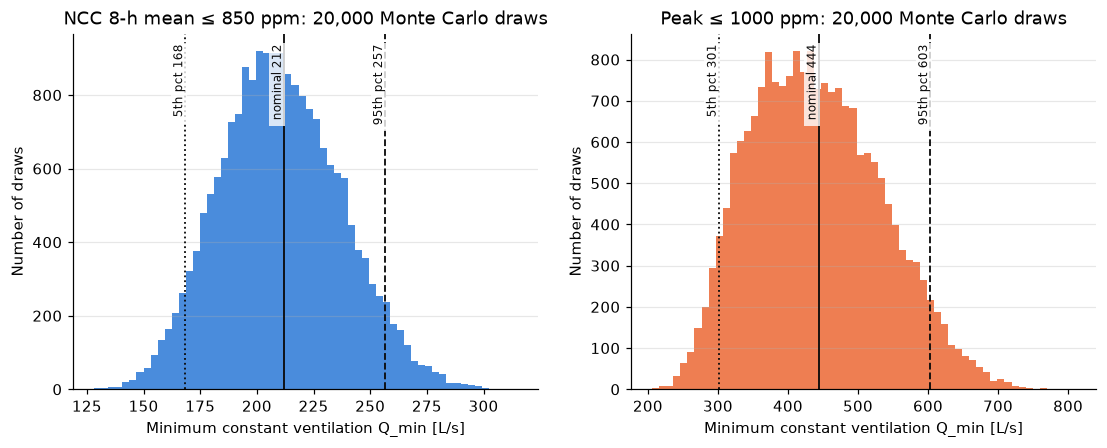

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, crit, color, title in [(axes[0], "8h", C["blue"], "NCC 8-h mean ≤ 850 ppm"),
                               (axes[1], "peak", C["orange"], "Peak ≤ 1000 ppm")]:
    v = mc[crit]
    ax.hist(v, bins=60, color=color, alpha=0.85)
    nom = Q8_NOM if crit == "8h" else QP_NOM
    p5, p95 = np.percentile(v, [5, 95])
    ymax = ax.get_ylim()[1]
    for x, ls, lab in [(nom, "-", f"nominal {nom:.0f}"), (p5, ":", f"5th pct {p5:.0f}"), (p95, "--", f"95th pct {p95:.0f}")]:
        ax.axvline(x, color=C["ink"], ls=ls, lw=1.2)
        ax.text(x, ymax * 0.97, f" {lab}", fontsize=8, rotation=90, va="top", ha="right", color=C["ink"],
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1})
    ax.set_xlabel("Minimum constant ventilation Q_min [L/s]")
    ax.set_ylabel("Number of draws")
    ax.set_title(f"{title}: {N_MC:,} Monte Carlo draws")
    ax.grid(axis="x", visible=False)
save(fig, "stage5_mc_distributions")

### Has the Monte Carlo converged?

A Monte Carlo estimate has a random error that shrinks like $1/\sqrt{n}$. The standard error of the mean is $s/\sqrt{n}$. The plot shows the running estimates of the mean and the 95th percentile as more draws are added.

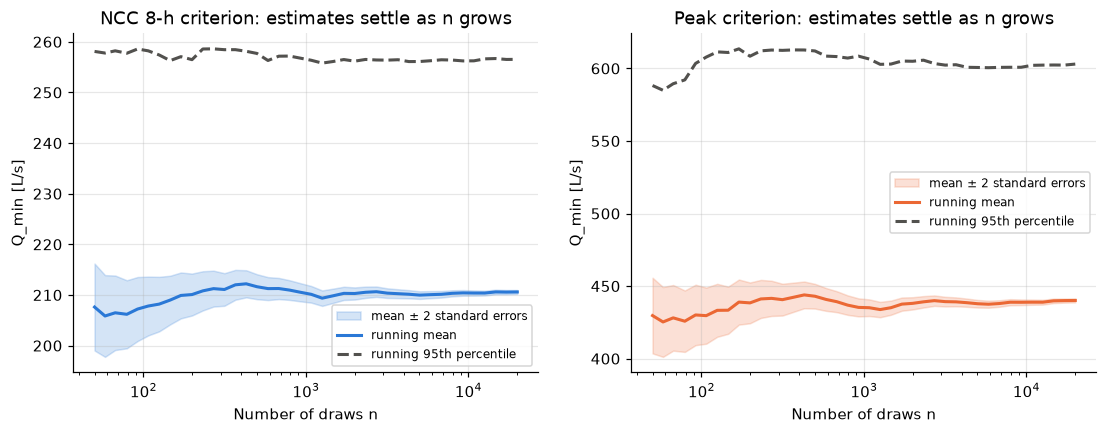

8h  : standard error of the mean with n = 1000: 0.86 L/s; with n = 20000: 0.19 L/s (ratio 4.55, theory sqrt(20) = 4.47)
peak: standard error of the mean with n = 1000: 2.99 L/s; with n = 20000: 0.66 L/s (ratio 4.55, theory sqrt(20) = 4.47)


In [9]:
ns = np.unique(np.geomspace(50, N_MC, 40).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, crit, color in [(axes[0], "8h", C["blue"]), (axes[1], "peak", C["orange"])]:
    v = mc[crit]
    means = np.array([v[:n].mean() for n in ns])
    sems = np.array([v[:n].std(ddof=1) / np.sqrt(n) for n in ns])
    p95 = np.array([np.percentile(v[:n], 95) for n in ns])
    ax.fill_between(ns, means - 2 * sems, means + 2 * sems, color=color, alpha=0.2, label="mean ± 2 standard errors")
    ax.semilogx(ns, means, color=color, label="running mean")
    ax.semilogx(ns, p95, color=C["grey"], ls="--", label="running 95th percentile")
    ax.set_xlabel("Number of draws n")
    ax.set_ylabel("Q_min [L/s]")
    ax.set_title(f"{'NCC 8-h' if crit == '8h' else 'Peak'} criterion: estimates settle as n grows")
    ax.legend(fontsize=8)
save(fig, "stage5_mc_convergence")
for crit in ("8h", "peak"):
    s = percentile_summary(mc[crit][:1000])
    print(f"{crit:4s}: standard error of the mean with n = 1000: {s['sem']:.2f} L/s; with n = {N_MC}: "
          f"{percentile_summary(mc[crit])['sem']:.2f} L/s (ratio {s['sem'] / percentile_summary(mc[crit])['sem']:.2f}, "
          f"theory sqrt(20) = {np.sqrt(20):.2f})")

### Probability of compliance, and which inputs drive the spread

Because CO2 falls monotonically with $Q$, a constant rate $Q$ complies exactly when $Q \ge Q_{min}$. The probability that a chosen rate complies is therefore the fraction of draws with $Q_{min} \le Q$: the cumulative distribution of $Q_{min}$.

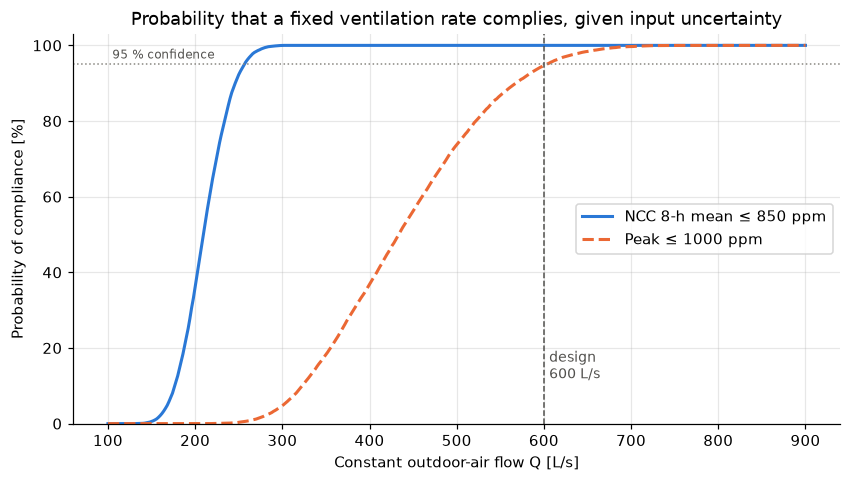

Rate meeting the NCC criterion with 95 % confidence:  257 L/s (1.21 x nominal Q_min, 43 % of design)
Rate meeting the peak criterion with 95 % confidence: 603 L/s (1.36 x nominal Q_min, 101 % of design)


In [10]:
q_axis = np.linspace(100, 900, 401)
fig, ax = plt.subplots(figsize=(9, 4.6))
for crit, color, ls, label in [("8h", C["blue"], "-", "NCC 8-h mean ≤ 850 ppm"), ("peak", C["orange"], "--", "Peak ≤ 1000 ppm")]:
    prob = np.searchsorted(np.sort(mc[crit]), q_axis, side="right") / N_MC
    ax.plot(q_axis, 100 * prob, color=color, ls=ls, label=label)
ax.axhline(95, color=C["light"], lw=1, ls=":")
ax.text(105, 96.5, "95 % confidence", fontsize=8, color=C["grey"])
ax.axvline(Q_DESIGN, color=C["grey"], lw=1, ls="--")
ax.text(Q_DESIGN + 6, 12, f"design\n{Q_DESIGN:.0f} L/s", fontsize=9, color=C["grey"])
ax.set_xlabel("Constant outdoor-air flow Q [L/s]")
ax.set_ylabel("Probability of compliance [%]")
ax.set_ylim(0, 103)
ax.set_title("Probability that a fixed ventilation rate complies, given input uncertainty")
ax.legend(loc="center right")
save(fig, "stage5_compliance_probability")

Q95 = {crit: float(np.percentile(mc[crit], 95)) for crit in mc}
print(f"Rate meeting the NCC criterion with 95 % confidence:  {Q95['8h']:.0f} L/s "
      f"({Q95['8h'] / Q8_NOM:.2f} x nominal Q_min, {100 * Q95['8h'] / Q_DESIGN:.0f} % of design)")
print(f"Rate meeting the peak criterion with 95 % confidence: {Q95['peak']:.0f} L/s "
      f"({Q95['peak'] / QP_NOM:.2f} x nominal Q_min, {100 * Q95['peak'] / Q_DESIGN:.0f} % of design)")

8h   vs V    : r = -0.07
8h   vs G    : r = +0.66
8h   vs C_out: r = +0.34
8h   vs k    : r = +0.66
peak vs V    : r = -0.66
peak vs G    : r = +0.51
peak vs C_out: r = +0.19
peak vs k    : r = +0.51


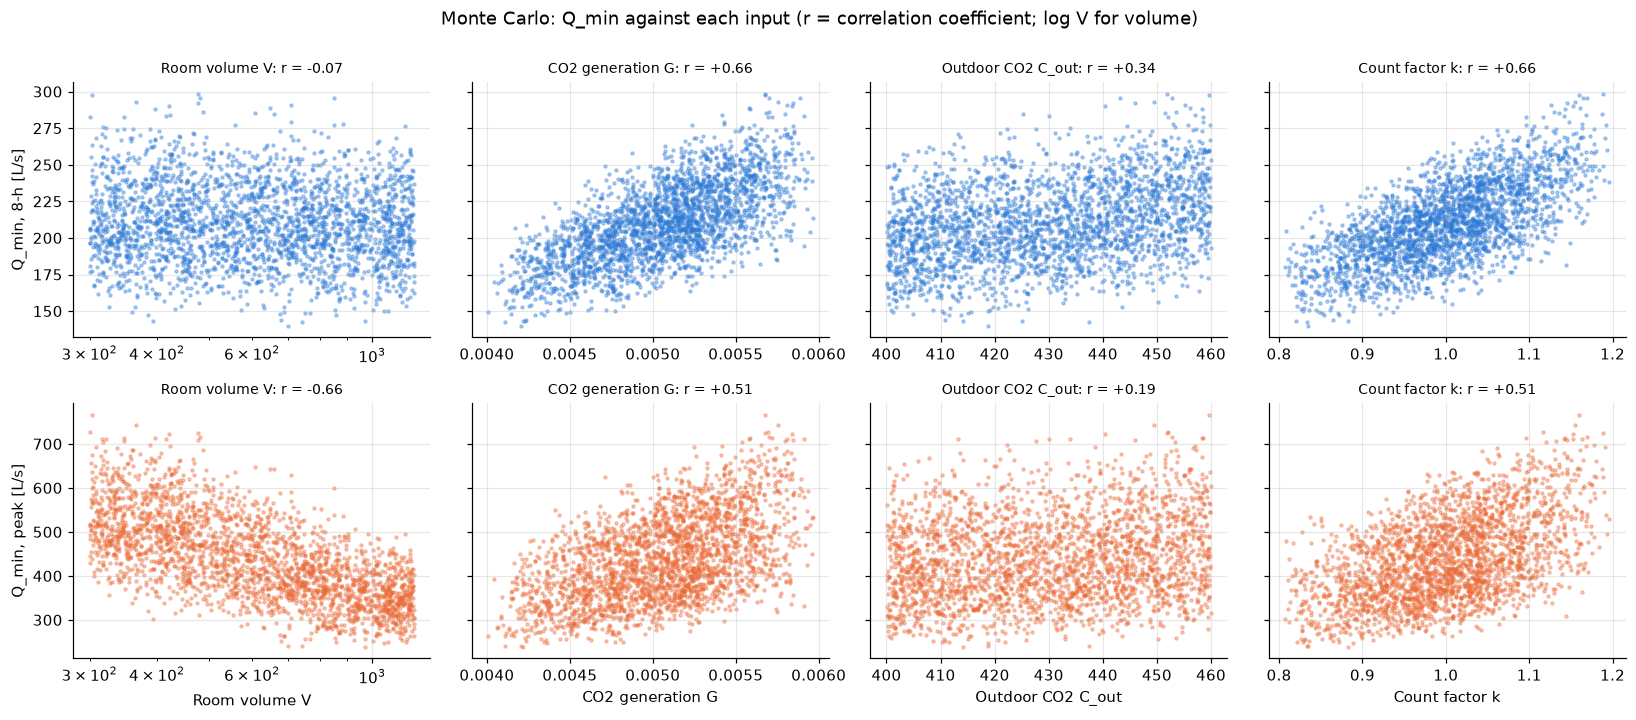

In [11]:
sub = np.random.default_rng(1).choice(N_MC, 2500, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey="row")
for row, (crit, color) in enumerate([("8h", C["blue"]), ("peak", C["orange"])]):
    for col, name in enumerate(NOMINAL):
        ax = axes[row, col]
        x, y = S[name], mc[crit]
        r = np.corrcoef(np.log(x) if name == "V" else x, y)[0, 1]
        ax.scatter(x[sub], y[sub], s=4, alpha=0.35, color=color, rasterized=True)
        if name == "V":
            ax.set_xscale("log")
        ax.set_title(f"{LABELS[name]}: r = {r:+.2f}", fontsize=9)
        print(f"{crit:4s} vs {name:5s}: r = {r:+.2f}")
        if row == 1:
            ax.set_xlabel(LABELS[name])
    axes[row, 0].set_ylabel(f"Q_min, {'8-h' if crit == '8h' else 'peak'} [L/s]")
fig.suptitle("Monte Carlo: Q_min against each input (r = correlation coefficient; log V for volume)", y=1.0)
fig.tight_layout()
save(fig, "stage5_mc_scatter")

**What this shows.**

* The interpolated answers match full root finding to a small fraction of a percent, far below the spread caused by the inputs.
* With all inputs uncertain together, the 5th–95th percentile range of $Q_{min,8h}$ is about −20 % to +21 % of nominal, and that of $Q_{min,peak}$ is wider, about −32 % to +36 %. The nominal value is close to the median, so nearly half the draws (46 %) need **more** air than the nominal $Q_{min}$. A design based only on nominal inputs would therefore be met with only about 54 % confidence.
* The rate needed for **95 % confidence** is the defensible design number. For the NCC criterion it is about 257 L/s, still well below the 600 L/s design rate, which passes in every draw. For the **peak** criterion the 95 % rate is about 600 L/s, essentially the design rate itself: the design rate fails the peak criterion in about 5 % of draws.
* The estimates settle as $n$ grows, and the standard error falls as $1/\sqrt n$ (the ratio for $n$ = 1000 vs 20 000 matches $\sqrt{20}$).
* The scatter plots confirm Section D: $Q_{min,8h}$ follows $G$, $k$ and $C_{out}$ and ignores $V$, while for $Q_{min,peak}$ the room volume shows the **strongest** correlation of all ($r \approx -0.66$). Its range (a factor of 4) is the widest of the four inputs.

## G. Numerical sensitivity

Sections D–F concern *physical* uncertainty. The answers also depend on *numerical* choices. These should have a negligible effect, otherwise the method itself would be a source of error.

### G1. Solver: does it matter that Stage 4 used the exact solution?

Repeat the $Q_{min}$ root finding, but evaluate $F$ with explicit Euler and with RK4 (step $h$ = 60 s) instead of the exact solution. The root finder is the bracketed secant method in $u = 1/Q$, as in Stage 4.

In [12]:
P_NOM = RoomParameters(NOMINAL["V"], NOMINAL["C_out"], NOMINAL["G"])

def q_min_with_solver(solver, criterion):
    key, limit = CRITERIA[criterion]
    def F_u(u):  # u = 1/Q
        q = 1.0 / u
        c = solver(occ, q, P_NOM, DT)
        return compliance_metrics(step_mean_concentration(c, occ, q, P_NOM, DT), DT)[key] - limit
    lo, hi = 50.0, 1000.0
    r = secant_bracketed(F_u, 1.0 / hi, 1.0 / lo, x_tol=0.01 / hi**2, f_tol=0.01)
    return 1.0 / r.root, r.evaluations

rows = []
for name, solver in [("explicit Euler", explicit_euler), ("RK4", rk4)]:
    t0 = time.perf_counter()
    for crit in ("8h", "peak"):
        q, n_eval = q_min_with_solver(solver, crit)
        nom = Q8_NOM if crit == "8h" else QP_NOM
        rows.append({"solver": name, "criterion": crit, "Q_min [L/s]": q, "vs exact [L/s]": q - nom,
                     "vs exact [%]": 100 * (q / nom - 1), "ODE solves": n_eval})
    print(f"{name}: {time.perf_counter() - t0:.1f} s")
solver_table = pd.DataFrame(rows)
print(solver_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
mc_sd = {crit: float(np.std(mc[crit])) for crit in mc}
print(f"\nFor scale: Monte Carlo standard deviation of Q_min = {mc_sd['8h']:.1f} L/s (8-h), {mc_sd['peak']:.1f} L/s (peak)")

explicit Euler: 4.5 s
RK4: 5.8 s
        solver criterion  Q_min [L/s]  vs exact [L/s]  vs exact [%]  ODE solves
explicit Euler        8h     211.9008          0.0403        0.0190           6
explicit Euler      peak     448.3453          4.6654        1.0515           8
           RK4        8h     211.8604         -0.0000       -0.0000           6
           RK4      peak     443.6878          0.0079        0.0018           7

For scale: Monte Carlo standard deviation of Q_min = 26.7 L/s (8-h), 92.9 L/s (peak)


### G2. Time resolution of the occupancy input

The 1-minute occupancy series is averaged into coarser bins (5–60 min). This conserves person-time exactly. The model is then solved on the coarser grid. Stage 3 showed that coarse bins **flatten peaks**. Here we see what that does to the design answer.

 bin [min]  Q_min,8h [L/s]  8h vs 1-min [%]  Q_min,peak [L/s]  peak vs 1-min [%]
         1          211.86             0.00            443.68               0.00
         5          211.86            -0.00            432.33              -2.56
        15          211.84            -0.01            417.65              -5.87
        30          211.79            -0.03            385.73             -13.06
        60          211.46            -0.19            330.38             -25.54


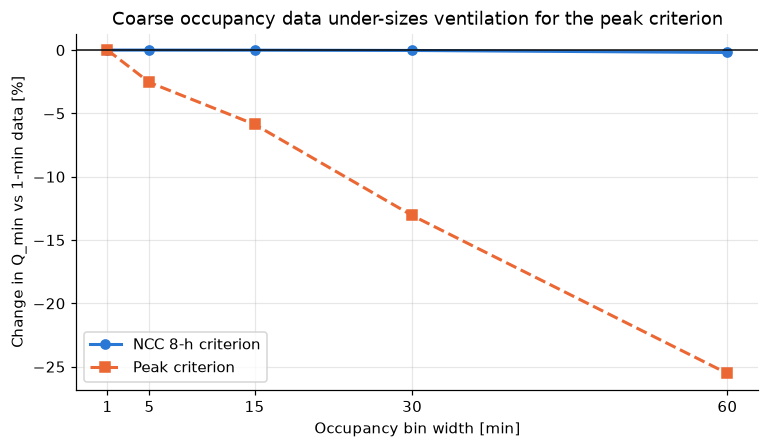

In [13]:
rows = []
for factor in (1, 5, 15, 30, 60):
    occ_c = aggregate_occupancy(occ, factor)
    dt_c = DT * factor
    p = RoomParameters(NOMINAL["V"], NOMINAL["C_out"], NOMINAL["G"])
    q8 = find_min_ventilation(occ_c, p, dt_c, criterion="8h", variable="inverse", bracket_lps=(20.0, 2000.0)).root
    qp = find_min_ventilation(occ_c, p, dt_c, criterion="peak", variable="inverse", bracket_lps=(20.0, 2000.0)).root
    rows.append({"bin [min]": factor, "Q_min,8h [L/s]": q8, "8h vs 1-min [%]": 100 * (q8 / Q8_NOM - 1),
                 "Q_min,peak [L/s]": qp, "peak vs 1-min [%]": 100 * (qp / QP_NOM - 1)})
res_table = pd.DataFrame(rows)
print(res_table.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(res_table["bin [min]"], res_table["8h vs 1-min [%]"], color=C["blue"], marker="o", label="NCC 8-h criterion")
ax.plot(res_table["bin [min]"], res_table["peak vs 1-min [%]"], color=C["orange"], marker="s", ls="--", label="Peak criterion")
ax.axhline(0, color=C["ink"], lw=1)
ax.set_xlabel("Occupancy bin width [min]")
ax.set_ylabel("Change in Q_min vs 1-min data [%]")
ax.set_xticks(res_table["bin [min]"])
ax.set_title("Coarse occupancy data under-sizes ventilation for the peak criterion")
ax.legend()
save(fig, "stage5_resolution")

### G3. Hold limits used in cleaning (Stage 1)

In Stage 1, a non-zero count with no new event for more than 2.5 h was treated as *unobserved*: the sensor may have stopped reporting. The longest real occupied hold in G.20 is 2.0 h. Here the occupied-hold limit is varied from 0.5 h to 4 h. Unobserved bins are filled with zero (an empty room), which is the assumption that lowers CO2 most. This needs the raw data (`data/raw/`); the section is skipped if it is not there.

In [14]:
raw_files = sorted((ROOT / "data" / "raw").glob("*ccupancy*.zip")) + sorted((ROOT / "data" / "raw").glob("*ccupancy*.csv"))
if not raw_files:
    print("Raw data not found in data/raw/: section G3 skipped.")
else:
    t0 = time.perf_counter()
    raw = read_occupancy_events(raw_files[0], [get_room("G20").floorspace_id])
    events, _ = clean_events(raw)
    print(f"Read and cleaned {len(events):,} G.20 events from {raw_files[0].name} in {time.perf_counter() - t0:.0f} s")
    rows = []
    for hold in ("0.5h", "1h", "1.5h", "2h", "2.5h", "4h"):
        g, rep = resample_occupancy(events, ResampleSettings(max_occupied_hold=hold))
        occ_h, dt_h, n_filled = occupancy_from_grid(g, fill="zero")
        rows.append({"occupied hold limit": hold, "holds cut short": rep["occupied_holds_truncated"],
                     "bins filled with 0": n_filled, "person-hours": rep["person_hours_observed"],
                     "Q_min,8h [L/s]": find_min_ventilation(occ_h, P_NOM, dt_h, variable="inverse",
                                                            bracket_lps=(20.0, 2000.0)).root,
                     "Q_min,peak [L/s]": find_min_ventilation(occ_h, P_NOM, dt_h, criterion="peak", variable="inverse",
                                                              bracket_lps=(20.0, 2000.0)).root})
    hold_table = pd.DataFrame(rows)
    print(hold_table.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Read and cleaned 1,894,867 G.20 events from 5occupancySensor_MayToDec2024_9MRows.zip in 21 s
occupied hold limit  holds cut short  bins filled with 0  person-hours  Q_min,8h [L/s]  Q_min,peak [L/s]
               0.5h              123                1753      16587.61          211.86            443.68
                 1h               21                 315      16613.67          211.86            443.68
               1.5h                3                  41      16618.46          211.86            443.68
                 2h                0                   0      16619.19          211.86            443.68
               2.5h                0                   0      16619.19          211.86            443.68
                 4h                0                   0      16619.19          211.86            443.68


**What this shows.**

* **Solver (G1):** RK4 reproduces the exact $Q_{min}$ to within 0.01 L/s. Explicit Euler shifts the 8-hour value by only 0.04 L/s, but the peak value by about 1 % (about 5 L/s). Euler's error is largest where CO2 changes fastest, which is during crowd peaks, and a first-order method makes a larger error there. Even so, that shift is about 20 times smaller than the Monte Carlo spread (standard deviation 93 L/s). The exact solution used in Stage 4 removes this error completely.
* **Time resolution (G2):** the 8-hour criterion is insensitive to the bin width, because averaging inside an 8-hour window conserves person-time. The **peak** criterion, however, is under-estimated when the data are coarse, because the short crowd peaks are smoothed away, so the required ventilation is under-sized. Keeping 1-minute data is therefore a **safety** issue for the peak criterion, not just a matter of precision.
* **Hold limits (G3):** $Q_{min}$ is unchanged even when the limit is cut to 0.5 h, which removes about 30 person-hours from the record. The holds that get cut short happen at quiet times, not in the busy periods that set the design. The cleaning choice does not affect the answer.

## H. Engineering interpretation and limitations

**Which parameters matter most?** (This is a question from the brief's sample interview questions.)

1. For the **NCC 8-hour criterion**, the CO2 generation rate $G$ and the people-counter accuracy $k$ dominate, with equal effect because only $kG$ matters. Outdoor CO2 comes next. The room volume, the least certain input, has almost no effect, because the 8-hour criterion is set by near-steady conditions.
2. For the **1000 ppm peak criterion**, $kG$ still leads, but the **room volume becomes equally important**, because short crowded events are buffered by the air in the room. The peak design rate is therefore the least certain result.
3. **DCV** needs about $10^6 kG/(850 - C_{out})$ L/s per person, independent of $V$. Its uncertainty is the uncertainty in $kG$ and $C_{out}$: roughly ±20 % over the stated ranges.
4. **Numerical choices** (solver, hold limits) are small compared with the input uncertainty. The exception is **coarse occupancy data**, which under-sizes ventilation for the peak criterion by up to about 25 % (60-minute bins).

**Design recommendation (G.20, under the stated input ranges):**

* The nominal $Q_{min}$ meets each criterion with only about 54 % confidence. Use the **95th-percentile** value for a robust design: about 1.2× nominal for the NCC criterion (about 257 L/s), and about 1.36× nominal for the peak criterion (about 600 L/s) (Section F).
* The existing 600 L/s design rate meets the NCC criterion in every Monte Carlo draw, and the peak criterion in about 95 % of draws. The energy case for DCV (Stage 4) stands, but it relies on the people counters: a counter that under-counts by 20 % gives 20 % too little air unless $q_p$ is raised to match.
* The most valuable measurement to reduce uncertainty would be **$kG$**: a short CO2 logging campaign would calibrate it directly (Section C shows this is the combination the data can identify). The room volume should be measured for the peak criterion only.

**Limitations of this analysis**

* The input ranges and distributions are **judgements**, not measured statistics. The Monte Carlo spread is only as good as these assumptions. They are stated in Section B so they can be challenged.
* The inputs are sampled **independently**. A correlation (for example, crowded events with higher activity, and so higher $G$) would widen the spread.
* $G$ and $k$ are treated as constant over two years. Real activity levels and counter errors vary with time.
* The model-form assumptions (well-mixed air, no measured CO2, an assumed space-ID mapping) are **not** covered by a parameter sensitivity study. They remain the main limitation (Stage 4, Section I).